# Лабораторная работа по NumPy

```text
python labs 3/
├── solve.ipynb
├── start.dat
├── lunar_images/
│   ├── lunar01_raw.jpg
│   ├── lunar02_raw.jpg
│   └── lunar03_raw.jpg
└── signals/
    ├── signal01.dat
    ├── signal02.dat
    └── signal03.dat
```

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

images_dir = Path('lunar_images')
signals_dir = Path('signals')

## Эпизод 1. Повышение контраста изображений Луны

Растягиваем исходный диапазон значений пикселей $[a,b]$ до $[0,255]$:

$$I_{\text{new}}=\frac{I-a}{b-a}\cdot255.$$

Исходные картинки не изменяются.

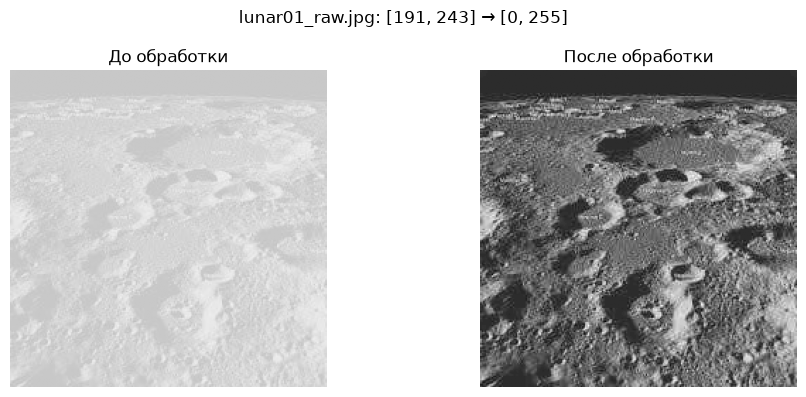

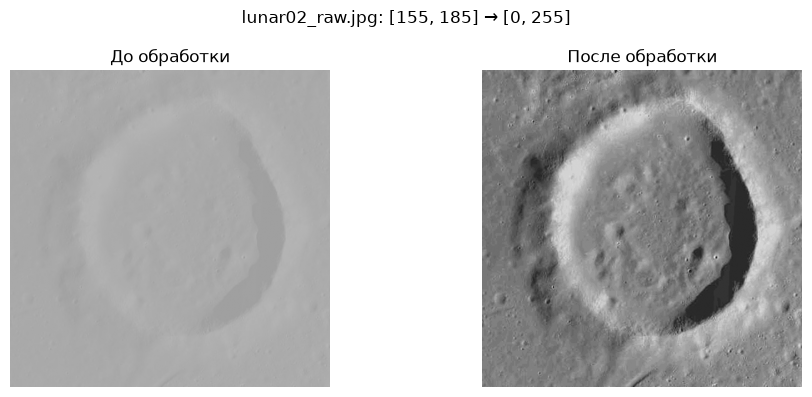

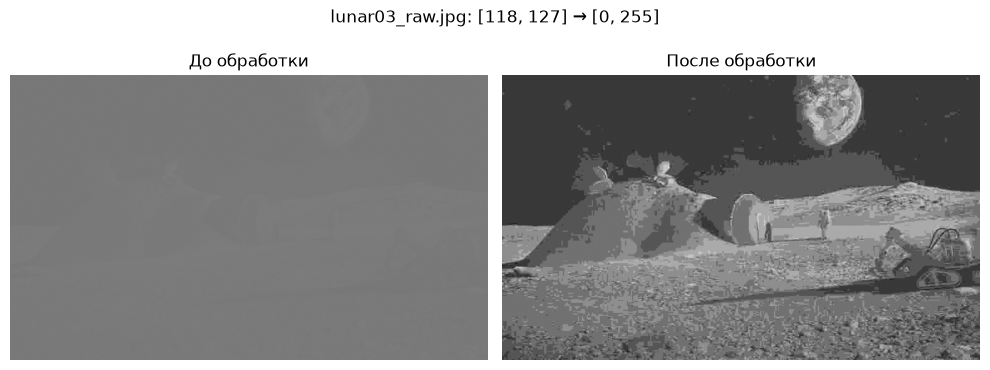

In [9]:
for path in sorted(images_dir.glob('*.jpg')):
    original = np.array(Image.open(path).convert('L'))
    a, b = original.min(), original.max()

    if a == b:
        result = np.zeros_like(original)
    else:
        result = np.rint((original.astype(float) - a) * 255 / (b - a)).astype(np.uint8)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(original, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title('До обработки')
    axes[1].imshow(result, cmap='gray', vmin=0, vmax=255)
    axes[1].set_title('После обработки')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(f'{path.name}: [{a}, {b}] → [{result.min()}, {result.max()}]')
    plt.tight_layout()
    plt.show()

## Эпизод 2. Фильтрация сигналов

Скользящее среднее: для каждого отсчёта берётся не более **10 последних значений**, включая текущее. Для первых девяти отсчётов используются все доступные предыдущие показания. Суммы считаем через `np.cumsum`.

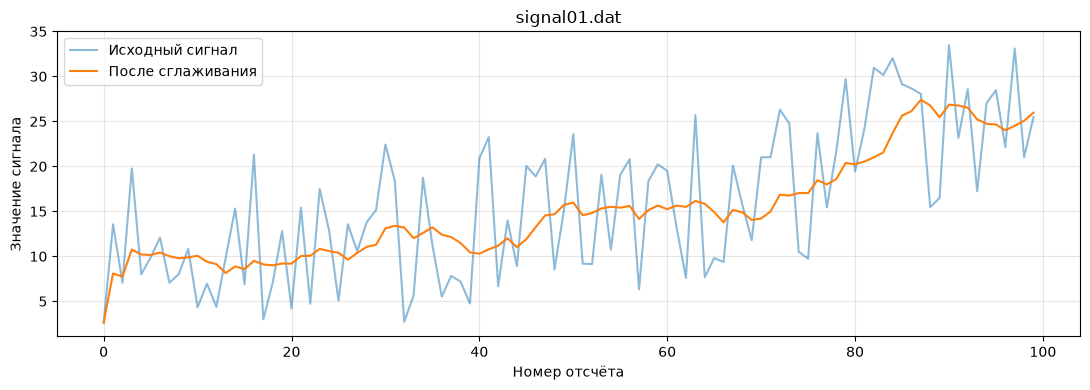

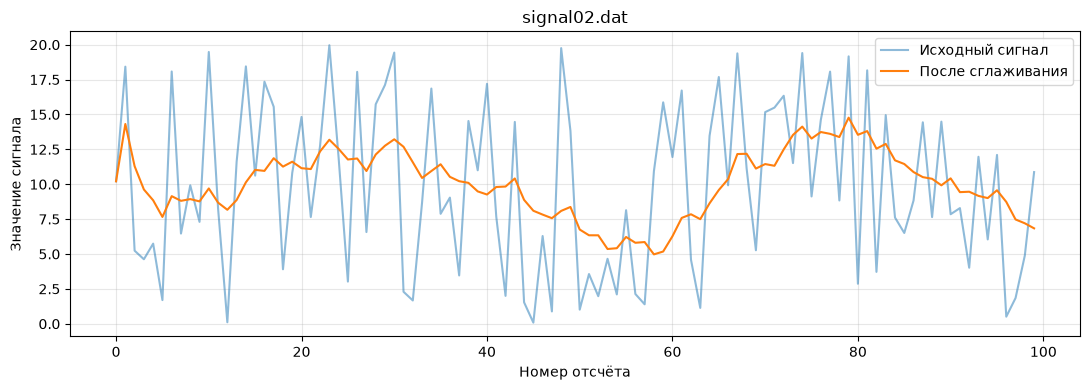

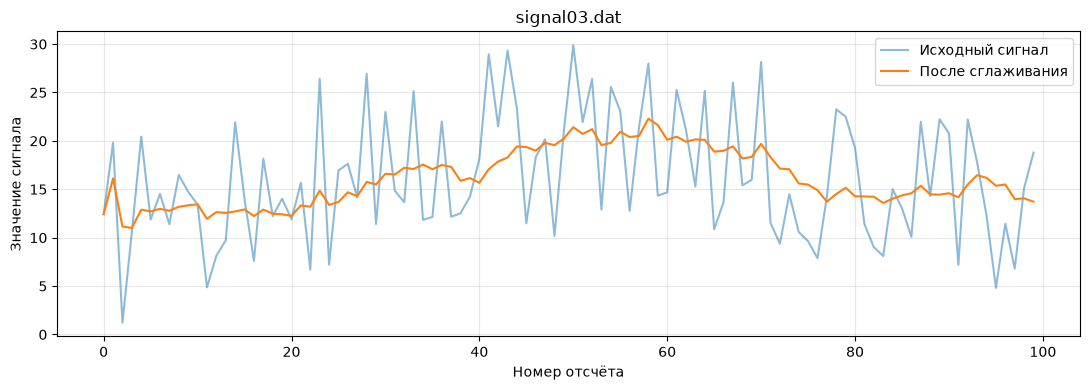

In [10]:
for path in sorted(signals_dir.glob('signal*.dat')):
    signal = np.loadtxt(path).ravel()
    n = np.arange(len(signal))
    left = np.maximum(0, n - 9)
    sums = np.r_[0, np.cumsum(signal)]
    filtered = (sums[n + 1] - sums[left]) / (n - left + 1)

    plt.figure(figsize=(11, 4))
    plt.plot(n, signal, alpha=0.5, label='Исходный сигнал')
    plt.plot(n, filtered, label='После сглаживания')
    plt.title(path.name)
    plt.xlabel('Номер отсчёта')
    plt.ylabel('Значение сигнала')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

## Эпизод 3. Моделирование процесса за 255 шагов

Начальные значения считываются из **`start.dat`** рядом с ноутбуком.

Из условия:

$$\vec{u}^{\,n+1}=\vec{u}^{\,n}-0.5\,A\vec{u}^{\,n}.$$

В матрице $A$ на главной диагонали находятся единицы, слева от неё — $-1$, причём в верхнем правом углу тоже стоит $-1$ (циклический перенос). Поэтому:

$$A\vec{u}=\vec{u}-\operatorname{roll}(\vec{u},1).$$

Это позволяет выполнить расчёт средствами NumPy без явного построения матрицы $A$. Храним начальное состояние и все **255 последующих** состояний.

In [11]:
data = np.loadtxt('start.dat')
if data.ndim == 2 and data.shape[1] == 2:
    x, u0 = data.T
else:
    u0 = data.ravel()
    x = np.arange(len(u0))

alpha = 0.5
history = np.empty((256, len(u0)))
history[0] = u0

for step in range(255):
    history[step + 1] = history[step] - alpha * (history[step] - np.roll(history[step], 1))

print('Вычислено шагов:', len(history) - 1)

Вычислено шагов: 255


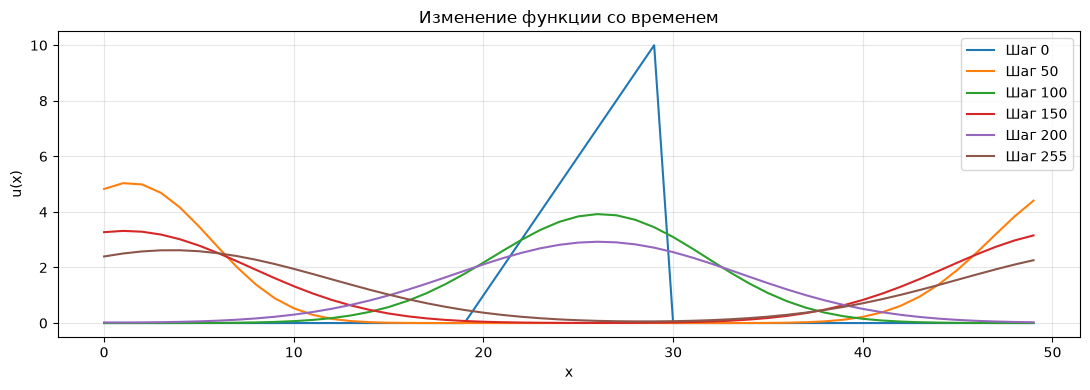

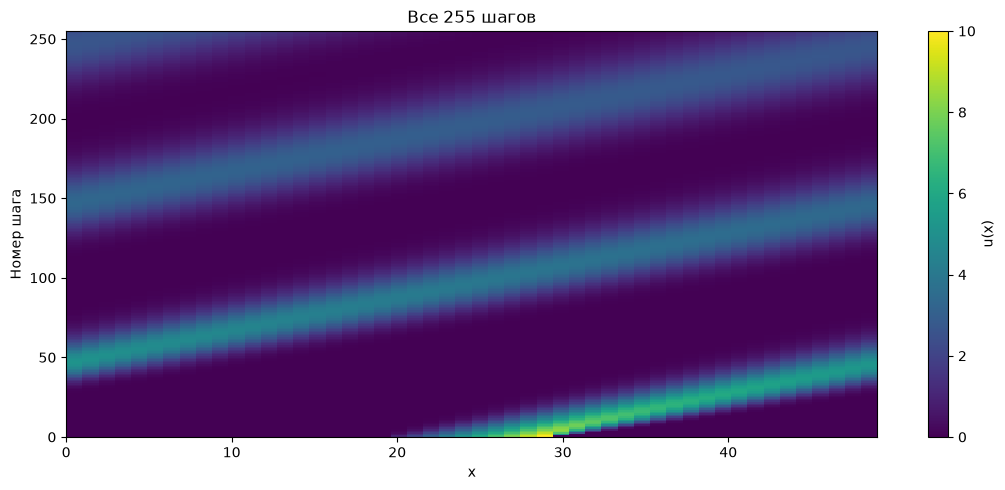

In [12]:
plt.figure(figsize=(11, 4))
for step in [0, 50, 100, 150, 200, 255]:
    plt.plot(x, history[step], label=f'Шаг {step}')
plt.title('Изменение функции со временем')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
plt.imshow(history, aspect='auto', origin='lower', interpolation='nearest',
           extent=[x[0], x[-1], 0, 255])
plt.xlabel('x')
plt.ylabel('Номер шага')
plt.title('Все 255 шагов')
plt.colorbar(label='u(x)')
plt.tight_layout()
plt.show()

### Анимация

Анимация воспроизводится непосредственно в Jupyter, без создания GIF или других файлов.

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.5), dpi=80)
line, = ax.plot(x, history[0])
ax.set_xlim(x.min(), x.max())
lo, hi = history.min(), history.max()
pad = 0.05 * (hi - lo) if hi > lo else 1
ax.set_ylim(lo - pad, hi + pad)
ax.set_xlabel('x')
ax.set_ylabel('u(x)')
ax.grid(alpha=0.3)


def update(frame):
    line.set_ydata(history[frame])
    ax.set_title(f'Шаг {frame} / 255')
    return line,

animation = FuncAnimation(fig, update, frames=256, interval=60)
plt.close(fig)
display(HTML(animation.to_jshtml()))